[![Text: CC BY-SA 4.0](https://img.shields.io/badge/text-CC%20BY--SA%204.0-lightgrey.svg)](https://creativecommons.org/licenses/by-sa/4.0/)
[![Code: MIT](https://img.shields.io/badge/code-MIT-yellow.svg)](https://opensource.org/license/mit)

This notebook is part of course materials for CS 545: Machine Learning at
Colorado State University. These notebooks are based on the PyTorch version of
[Dive into Deep Learning](https://d2l.ai) by Aston Zhang, Zachary C. Lipton,
Mu Li and Alexander J. Smola, used under
[CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/) and heavily
modified by [Asa Ben-Hur](https://www.cs.colostate.edu/~asa/) with
[Claude](https://claude.com) AI. The text is released under
[CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/); the code is
released under the [MIT license](https://opensource.org/license/mit).

# Sentiment Analysis Using a Transformer

Recurrent networks are slow to train not because they do too many operations, but because the update equation $\mathbf{H}_t = f(\mathbf{X}_t, \mathbf{H}_{t-1})$ forces those operations into a serial chain.  Here, we will see an architecture that, like the RNN, lets every position's representation depend on the entire sequence, but computes all positions **in parallel**.  That architecture is the **transformer**, whose central operation is called **self-attention**.

In this notebook we treat the transformer as a *black box*: we take the sentiment classifier from the previous module, and replace the bidirectional LSTM with a transformer module using PyTorch's built-in implementation.  Everything else stays the same: the same IMDb data pipeline, the same embedding layer, the same training loop. In the notebooks that follow we first build intuition for what attention accomplishes, then open the box and reveal the details.

The architecture has the same three stages as the RNN classifier:

1. An **embedding layer** that maps each token ID to a vector.
2. An **encoder**, previously a bidirectional LSTM, now a transformer — transforms the sequence of token vectors so that each position's vector reflects the whole review.
3. A **linear layer** maps a fixed-length representation of the review to the two class scores.

The overall structure is the same, including the interface of the encoder — a sequence of vectors in, a sequence of vectors out, each output informed by the entire input.  What differs is *how* information moves between positions, and that difference is the subject of this module.  The figure below makes the comparison concrete.

In [1]:
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

import collections
import os
import re
import tarfile
import time
import urllib.request

import numpy as np
import torch
from torch import nn
from matplotlib import pyplot as plt

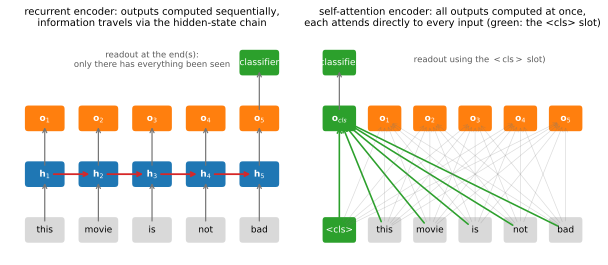

In [15]:
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, text, color='C0', tc='white', w=0.62, h=0.34):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h,
                                boxstyle='round,pad=0.06',
                                facecolor=color, edgecolor='none'))
    ax.text(x, y, text, ha='center', va='center', color=tc, fontsize=9)

def arrow(ax, x0, y0, x1, y1, color='0.45', lw=1.2, alpha=1.0):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle='->', color=color, lw=lw,
                                alpha=alpha, shrinkA=9, shrinkB=9))

words = ['this', 'movie', 'is', 'not', 'bad']
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.8))

# left: recurrent encoder
ax = axes[0]
for i, wd in enumerate(words):
    box(ax, i, 0, wd, color='0.85', tc='black')          # input tokens
    box(ax, i, 1, f'$\\mathbf{{h}}_{i+1}$', color='C0')  # hidden states
    box(ax, i, 2, f'$\\mathbf{{o}}_{i+1}$', color='C1')  # outputs
    arrow(ax, i, 0, i, 1)                                # input -> hidden
    arrow(ax, i, 1, i, 2)                                # hidden -> output
    if i > 0:                                            # the recurrence
        arrow(ax, i - 1, 1, i, 1, color='C3', lw=1.8)
box(ax, len(words) - 1, 3, 'classifier', color='C2')
arrow(ax, len(words) - 1, 2, len(words) - 1, 3)
ax.text(2, 3.05, 'readout at the end(s):\nonly there has everything been seen',
        ha='center', va='center', fontsize=8.5, color='0.35')
ax.set_title('recurrent encoder: outputs computed sequentially,\n'
             'information travels via the hidden-state chain',
             fontsize=10)

# right: self-attention encoder
ax = axes[1]
words_cls = ['<cls>'] + words
for i, wd in enumerate(words_cls):
    box(ax, i, 0, wd, color='C2' if i == 0 else '0.85',
        tc='white' if i == 0 else 'black')               # input tokens
    box(ax, i, 2, f'$\\mathbf{{o}}_{i}$' if i else '$\\mathbf{o}_{cls}$',
        color='C2' if i == 0 else 'C1')                  # outputs
# every output attends to every input; highlight <cls>, fade the rest
for j in range(len(words_cls)):
    for i in range(len(words_cls)):
        if j == 0:
            arrow(ax, i, 0, j, 2, color='C2', lw=1.6)
        else:
            arrow(ax, i, 0, j, 2, color='0.45', lw=0.7, alpha=0.25)
box(ax, 0, 3, 'classifier', color='C2')
arrow(ax, 0, 2, 0, 3)
ax.text(3.1, 3.05, 'readout using the $\\mathdefault{<cls>}$ slot)',
        ha='center', va='center', fontsize=8.5, color='0.35')
ax.set_title('self-attention encoder: all outputs computed at once,\n'
             'each attends directly to every input (green: the <cls> slot)',
             fontsize=10)

for ax, n in zip(axes, [len(words), len(words_cls)]):
    ax.set_xlim(-0.7, n - 0.3)
    ax.set_ylim(-0.5, 3.55)
    ax.axis('off')
plt.tight_layout()

Both architectures have the same overall structure: one input token per position, one output vector per position, and a classifier that reads a summary of the sequence.  The differences:  In the recurrent encoder (left), outputs are produced sequentially, and information about other positions arrives only by traveling along the hidden-state chain; a word's influence on a distant output must survive every intermediate step.  (Our BiLSTM ran a second chain right-to-left, omitted here, which is why it read the sequence out at *both* ends.)  In the self-attention encoder (right), all outputs can be computed in parallel, and each output draws *directly* on every input — the operation called attention, whose gray web of connections we will spend the next two notebooks understanding.

The right panel also shows one new token, `<cls>`, in the green box.  The classifier needs a single fixed-length vector for the whole review, and the transformer, unlike the LSTM, has no "state after reading everything" to grab.  Instead we prepend a special marker token and read the classification out of *its* output slot.  Since every output sees every input, that output slot can learn to summarize the review.

One caution about the right panel.  Only the `<cls>` output reaches the classifier.  So in a *one-layer* model, the outputs drawn at the word positions would be computed and then never used.  They become useful when encoder layers are *stacked* (our model uses two): the second layer consumes all of the first layer's outputs.

## Loading the data

The following cell repeats the IMDb pipeline used in the previous module — download, tokenize, build a vocabulary, truncate/pad to a fixed length, wrap in data iterators — with two changes.

First, the `<cls>` token: we add it to the vocabulary and prepend it to every review, so position 0 of every sequence holds the same "blank".  **Since it carries no content of its own, its output vector is free to become whatever summary of the review the classifier needs.**  (This trick comes from BERT, a model we will see at the end of the module.)  For it to work, the encoder must let position the `<cls>` token at position 0 gather information from every other position.

Second, we truncate/pad to 200 tokens rather than the 500 we used with the LSTM.  Recall from the length histogram in the dataset notebook that most reviews fit comfortably in 200 tokens, so little signal is lost.  As we will see, computation time for transformers increases quadratically with sequence length, so keeping sequences short will have a significant impact on the running time.

In [3]:
def download_imdb(data_dir='../data'):
    """Download and extract the IMDb review dataset."""
    # a fast mirror of https://ai.stanford.edu/~amaas/data/sentiment/
    url = 'https://d2l-data.s3-accelerate.amazonaws.com/aclImdb_v1.tar.gz'
    os.makedirs(data_dir, exist_ok=True)
    archive = os.path.join(data_dir, 'aclImdb_v1.tar.gz')
    if not os.path.exists(archive):
        print('downloading', url, '...')
        urllib.request.urlretrieve(url, archive)
    extracted = os.path.join(data_dir, 'aclImdb')
    if not os.path.exists(extracted):
        print('extracting ...')
        with tarfile.open(archive) as tar:
            tar.extractall(data_dir)
    return extracted

def read_imdb(data_dir, is_train):
    """Read the IMDb review dataset text sequences and labels."""
    data, labels = [], []
    for label in ('pos', 'neg'):
        folder_name = os.path.join(data_dir, 'train' if is_train else 'test',
                                   label)
        for file in os.listdir(folder_name):
            with open(os.path.join(folder_name, file), 'rb') as f:
                data.append(f.read().decode('utf-8').replace('\n', ''))
                labels.append(1 if label == 'pos' else 0)
    return data, labels

def tokenize(text):
    """Split a review into a list of lowercased word tokens."""
    text = text.replace('<br />', ' ').lower()
    return re.findall(r"[a-z0-9']+", text)

class Vocab:
    """A mapping between word tokens and integer indices."""
    def __init__(self, tokens, min_freq=0, reserved_tokens=[]):
        counter = collections.Counter(tok for line in tokens for tok in line)
        self.token_freqs = sorted(counter.items(), key=lambda x: x[1],
                                  reverse=True)
        self.idx_to_token = ['<unk>'] + reserved_tokens + [
            tok for tok, freq in self.token_freqs if freq >= min_freq]
        self.token_to_idx = {tok: idx
                             for idx, tok in enumerate(self.idx_to_token)}
    def __len__(self):
        return len(self.idx_to_token)
    def __getitem__(self, tokens):
        if isinstance(tokens, (list, tuple)):
            return [self[tok] for tok in tokens]
        return self.token_to_idx.get(tokens, self.unk)
    def to_tokens(self, indices):
        if hasattr(indices, '__len__'):
            return [self.idx_to_token[int(i)] for i in indices]
        return self.idx_to_token[int(indices)]
    @property
    def unk(self):
        return 0

def truncate_pad(line, num_steps, padding_token):
    """Truncate or pad a list of token IDs to exactly num_steps entries."""
    if len(line) > num_steps:
        return line[:num_steps]
    return line + [padding_token] * (num_steps - len(line))

def load_data_imdb(batch_size, num_steps=200):
    """Return data iterators and the vocabulary of the IMDb review dataset."""
    data_dir = download_imdb()
    train_data = read_imdb(data_dir, True)
    test_data = read_imdb(data_dir, False)
    train_tokens = [tokenize(review) for review in train_data[0]]
    test_tokens = [tokenize(review) for review in test_data[0]]
    vocab = Vocab(train_tokens, min_freq=5,
                  reserved_tokens=['<pad>', '<cls>'])
    # prepend <cls> to every review: position 0 is the summarization slot
    train_features = torch.tensor([
        truncate_pad([vocab['<cls>']] + vocab[line], num_steps,
                     vocab['<pad>'])
        for line in train_tokens])
    test_features = torch.tensor([
        truncate_pad([vocab['<cls>']] + vocab[line], num_steps,
                     vocab['<pad>'])
        for line in test_tokens])
    train_iter = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(train_features,
                                       torch.tensor(train_data[1])),
        batch_size, shuffle=True)
    test_iter = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(test_features,
                                       torch.tensor(test_data[1])),
        batch_size, shuffle=False)
    return train_iter, test_iter, vocab

batch_size = 64
num_steps = 200   # shorter than the 500 used with the LSTM -- see below
train_iter, test_iter, vocab = load_data_imdb(batch_size, num_steps)

In [4]:
# if you have a GPU we should enable it
# mps is the pytorch device that supports GPU computations on MacOS

device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device")

Using mps device


## The model, as a black box

PyTorch provides a complete transformer encoder: `nn.TransformerEncoder`, a stack of identical `nn.TransformerEncoderLayer` blocks.  For now we use it exactly the way we used `nn.LSTM`.  Each layer takes a batch of sequences of `d_model`-dimensional vectors and returns a batch of the same shape; stacking layers refines the representations.  Two hyperparameters will only make sense once we describe the model in detail — `nhead`, the number of *attention heads* per layer, and `dim_feedforward`, the width of an internal MLP.  That is the entire model: embedding layer, a multi-layer encoder, and linear readout to classify the sequence.

In [5]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, num_layers,
                 ffn_dim, num_classes, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=num_heads, dim_feedforward=ffn_dim,
            dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer,
                                             num_layers=num_layers)
        self.decoder = nn.Linear(d_model, num_classes)

    def forward(self, X):
        # X: (batch_size, num_steps) token IDs
        X = self.embedding(X)          # (batch_size, num_steps, d_model)
        X = self.encoder(X)            # (batch_size, num_steps, d_model)
        # read the review's representation out of the <cls> slot
        return self.decoder(X[:, 0, :])

Let's instantiate a model in the same size range as our BiLSTM (embedding dimension 100) with two encoder layers and four attention heads:

In [6]:
d_model = 100     # embedding / representation size, like embed_size before
num_heads = 4     # attention heads (mystery hyperparameter no. 1)
num_layers = 2    # stacked encoder layers
ffn_dim = 400     # width of the internal MLP (mystery hyperparameter no. 2)

model = TransformerClassifier(len(vocab), d_model, num_heads, num_layers,
                              ffn_dim, num_classes=2).to(device)

# named_parameters() pairs each parameter tensor with the dotted path of
# the module that owns it - a good way to see the contribution of each layer
for name, p in model.named_parameters():
    print(f'{name:50s} {str(tuple(p.shape)):>15s} {p.numel():>12,d}')
total = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'{"total":50s} {"":15s} {total:>12,d}')

embedding.weight                                      (30564, 100)    3,056,400
encoder.layers.0.self_attn.in_proj_weight               (300, 100)       30,000
encoder.layers.0.self_attn.in_proj_bias                     (300,)          300
encoder.layers.0.self_attn.out_proj.weight              (100, 100)       10,000
encoder.layers.0.self_attn.out_proj.bias                    (100,)          100
encoder.layers.0.linear1.weight                         (400, 100)       40,000
encoder.layers.0.linear1.bias                               (400,)          400
encoder.layers.0.linear2.weight                         (100, 400)       40,000
encoder.layers.0.linear2.bias                               (100,)          100
encoder.layers.0.norm1.weight                               (100,)          100
encoder.layers.0.norm1.bias                                 (100,)          100
encoder.layers.0.norm2.weight                               (100,)          100
encoder.layers.0.norm2.bias             

Each encoder layer contains something called `self_attn` (described in notebooks 3 and 4), two linear layers forming an MLP (`linear1`, `linear2` — width 400, our `dim_feedforward`), and two `norm` layers (see notebook 6).  Note also where the parameters are: the embedding layer dominates the count, just as it did for the BiLSTM, while each encoder layer is comparatively small.

## Training and evaluating the model

The training loop is identical to the one we used for the BiLSTM:

In [7]:
def accuracy(Y_hat, Y):
    """Fraction of correct predictions."""
    preds = Y_hat.argmax(dim=1).type(Y.dtype)
    return (preds == Y).float().mean()

In [8]:
lr = 0.001
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
loss_fn = nn.CrossEntropyLoss()

In [9]:
epochs = 10
loss_train, loss_valid, accuracy_valid = [], [], []
epoch_times = []
for epoch in range(epochs):
    start = time.time()
    model.train()
    loss_values = []
    for batch_X, batch_y in train_iter:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        preds = model(batch_X)
        loss = loss_fn(preds, batch_y)
        loss_values.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    loss_train.append(np.mean(loss_values))
    epoch_times.append(time.time() - start)
    model.eval()
    loss_values, accuracy_values = [], []
    for batch_X, batch_y in test_iter:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        with torch.no_grad():
            preds = model(batch_X)
            loss = loss_fn(preds, batch_y)
            loss_values.append(loss.item())
            accuracy_values.append(accuracy(preds, batch_y).item())
    loss_valid.append(np.mean(loss_values))
    accuracy_valid.append(np.mean(accuracy_values))
    print(f'epoch {epoch + 1:2d}  train loss {loss_train[-1]:.3f}  '
          f'val loss {loss_valid[-1]:.3f}  '
          f'val accuracy {accuracy_valid[-1]:.3f}  '
          f'({epoch_times[-1]:.1f} s)')

epoch  1  train loss 0.506  val loss 0.404  val accuracy 0.814  (44.0 s)
epoch  2  train loss 0.346  val loss 0.362  val accuracy 0.837  (41.7 s)
epoch  3  train loss 0.267  val loss 0.365  val accuracy 0.844  (41.8 s)
epoch  4  train loss 0.208  val loss 0.439  val accuracy 0.842  (41.9 s)
epoch  5  train loss 0.151  val loss 0.487  val accuracy 0.833  (42.0 s)
epoch  6  train loss 0.111  val loss 0.590  val accuracy 0.831  (41.7 s)
epoch  7  train loss 0.079  val loss 0.582  val accuracy 0.829  (41.9 s)
epoch  8  train loss 0.063  val loss 0.685  val accuracy 0.824  (41.6 s)
epoch  9  train loss 0.045  val loss 0.741  val accuracy 0.823  (43.0 s)
epoch 10  train loss 0.039  val loss 0.886  val accuracy 0.820  (42.1 s)


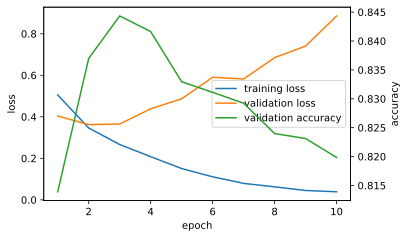

In [10]:
# loss and accuracy live on different scales, so give each its own y-axis
fig, ax1 = plt.subplots(figsize=(5.5, 3.5))
epochs_range = range(1, len(loss_train) + 1)
ax1.plot(epochs_range, loss_train, color='C0', label='training loss')
ax1.plot(epochs_range, loss_valid, color='C1', label='validation loss')
ax1.set_xlabel('epoch')
ax1.set_ylabel('loss')
ax2 = ax1.twinx()
ax2.plot(epochs_range, accuracy_valid, color='C2',
         label='validation accuracy')
ax2.set_ylabel('accuracy')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right');

Two things are worth reading off these curves.  First, convergence is fast: the model is close to its best validation accuracy within two or three epochs, noticeably sooner than the BiLSTM was.  Second, past that point the validation loss turns *upward* — and validation accuracy starts to slip — while the training loss keeps falling.  This is textbook **overfitting**, and the fact that validation loss degrades before validation accuracy does is itself informative: the model is not yet changing many of its decisions, but it is becoming increasingly *confident on the examples it gets wrong*, which cross-entropy punishes.  The transformer reaches this point sooner than the LSTM did for two reasons: its parallel, well-conditioned computation lets the optimizer make faster progress per epoch, and its all-pairs connectivity gives it ample capacity, and little built-in bias about how text should be processed, so once the generalizable signal is internalized, it moves on to memorizing training reviews.  In practice you would use early stopping, i.e. keep the parameters from the best-validation epoch or regularize harder; exercise 7 compares the options.

Let's also try the model on the same example sentences we used with the BiLSTM:

In [11]:
def predict_sentiment(net, vocab, sequence):
    """Predict the sentiment of a text sequence."""
    tokens = ['<cls>'] + tokenize(sequence)
    sequence = torch.tensor(vocab[tokens], device=device)
    label = torch.argmax(net(sequence.reshape(1, -1)), dim=1)
    return 'positive' if label == 1 else 'negative'

for text in ['this movie is so great', 'this movie is so bad',
             'this movie is not bad at all', 'this movie is mediocre']:
    print(f'{text!r:38s} -> {predict_sentiment(model, vocab, text)}')

'this movie is so great'               -> positive
'this movie is so bad'                 -> negative
'this movie is not bad at all'         -> negative
'this movie is mediocre'               -> negative


This looks similar to what we saw with the BiLSTM's.  Next, we will run an experiment that the RNN would pass without effort.

## An experiment: does word order matter?

Sentiment obviously depends on word order: "not bad at all" is praise, while the same words rearranged can be a pan.  Let's check whether the model uses order.  We keep `<cls>` in front (position 0 is our readout slot) and feed the model a review's words in their original order and in a scrambled order, printing the raw class scores rather than just the winning label:

In [12]:
def predict_logits(net, vocab, tokens):
    """Class scores for a list of word tokens (with <cls> prepended)."""
    X = torch.tensor(vocab[['<cls>'] + tokens], device=device).reshape(1, -1)
    with torch.no_grad():
        return net(X)[0]

model.eval()
original = tokenize('this movie is not bad at all')
scrambled = tokenize('bad at movie all this not is')   # same words!
print('original: ', predict_logits(model, vocab, original))
print('scrambled:', predict_logits(model, vocab, scrambled))
diff = (predict_logits(model, vocab, original)
        - predict_logits(model, vocab, scrambled)).abs().max().item()
print(f'largest difference: {diff:.2e}')

original:  tensor([ 4.0007, -3.2089], device='mps:0')
scrambled: tensor([ 4.0007, -3.2089], device='mps:0')
largest difference: 9.54e-07


The scores are *identical* — the tiny printed difference is floating-point rounding, orders of magnitude below anything the classifier could act on.  And nothing is special about this sentence: for *any* input, *any* reordering of the words leaves this model's output unchanged.  Our classifier is provably incapable of telling "not bad" from "bad... not", no matter how long we train it.  It reads reviews as *bags of words*.

Two things about this deserve a hard look.  First, how did an order-blind model match the BiLSTM's accuracy?  Because sentiment, it turns out, is mostly a bag-of-words task: the words "waste", "superb", "boring" carry most of the signal regardless of where they sit.  The comparable accuracy we just celebrated is partly a fact about the *task*, not only about the model.  Second, this is a genuine deficiency, and it is a *clue about the box*: whatever operation connects the positions inside the encoder must treat its input as an unordered set.  Real transformers repair this with a small standard addition to the input — but we will not install the repair until notebook 4, where we first diagnose the blindness precisely and then fix it.

## The speed question

The previous notebook's LSTM trained on 500-token sequences and ours on 200, so the epoch times printed above are not directly comparable.  For a sharp comparison — one that has nothing to do with training progress — we time a single forward/backward pass through the *same batch* for each architecture.  We rebuild the `BiRNN` class from the previous notebook for this purpose; its parameters are untrained, but timing does not care.

In [13]:
class BiRNN(nn.Module):
    """The bidirectional LSTM classifier from the previous module."""
    def __init__(self, vocab_size, embed_size, num_hiddens, num_layers):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.encoder = nn.LSTM(embed_size, num_hiddens,
                               num_layers=num_layers, bidirectional=True)
        self.decoder = nn.Linear(4 * num_hiddens, 2)

    def forward(self, inputs):
        embeddings = self.embedding(inputs.T)
        outputs, _ = self.encoder(embeddings)
        encoding = torch.cat((outputs[0], outputs[-1]), dim=1)
        return self.decoder(encoding)

def time_fwd_bwd(net, batch, repeats=3):
    """Median seconds for one forward+backward pass on a batch."""
    net = net.to(device)
    X = batch.to(device)
    times = []
    for _ in range(repeats + 1):  # first pass warms up; discard it
        if device == 'cuda':
            torch.cuda.synchronize()
        start = time.time()
        net.zero_grad()
        out = net(X)
        out.sum().backward()
        if device == 'cuda':
            torch.cuda.synchronize()
        times.append(time.time() - start)
    return np.median(times[1:])

batch_X, _ = next(iter(train_iter))
lstm = BiRNN(len(vocab), embed_size=100, num_hiddens=100, num_layers=2)
t_lstm = time_fwd_bwd(lstm, batch_X)
t_tsfm = time_fwd_bwd(model, batch_X)
print(f'BiLSTM:      {t_lstm * 1000:7.1f} ms per batch')
print(f'transformer: {t_tsfm * 1000:7.1f} ms per batch')
print(f'speedup:     {t_lstm / t_tsfm:.1f}x')

BiLSTM:         64.1 ms per batch
transformer:     4.8 ms per batch
speedup:     13.4x


The parameter counts are comparable — the transformer here actually has *more* parameters than the BiLSTM — yet it should process the batch substantially faster, for the reason we described at the end of the last module: the BiLSTM's computation over 200 positions is a chain of 200 small matrix multiplications, each waiting for the previous one, while the transformer's is a handful of *large* matrix multiplications spanning all positions at once, with no sequential dependency to wait on.  Modern hardware is built for exactly this shape of work.

If the speedup on your machine is smaller than expected — or the transformer even loses — the culprit is the other side of the trade: the cost of attention grows *quadratically* with sequence length, and not only in arithmetic but in **memory**.  Each layer materializes an attention-weight tensor of shape (batch, heads, $n$, $n$); at $n = 500$ that is $64 \times 4 \times 500 \times 500$ floats $\approx$ 256 MB per layer, while the LSTM's memory grows only linearly in $n$.  On a laptop GPU those tensors crowd out everything else.  This is precisely why we chose 200 tokens rather than 500 for this module.  Parallelism wins when the hardware has room to exploit it; the quadratic cost is the price attention pays for connecting every position to every other, and exercise 3 explores the crossover.

## A peek inside: what is the model looking at?

We will not open the box today, but we can rattle it.  The name "attention" suggests the model decides *which tokens to look at*.  It turns out each encoder layer computes, for every pair of positions $(i, j)$, a weight indicating how much position $i$ draws on position $j$ — and we can extract these weights and plot them.

The helper below reruns a review through the trained model and asks the first encoder layer's attention module to also return its weights.  (PyTorch computes them internally on every forward pass; it just doesn't return them unless asked.)

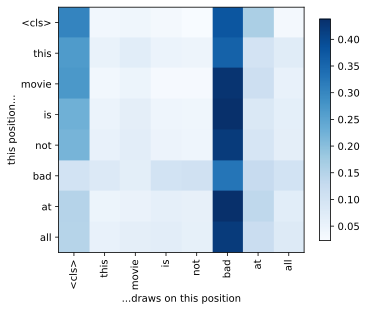

In [14]:
def attention_map(model, text, layer=0):
    """Attention weights of one encoder layer for a piece of text.
    Returns (tokens, weights) with weights of shape (len(tokens), len(tokens))
    averaged over the layer's heads."""
    model.eval()
    tokens = ['<cls>'] + tokenize(text)
    X = torch.tensor(vocab[tokens], device=device).reshape(1, -1)
    with torch.no_grad():
        h = model.embedding(X)
        for i, blk in enumerate(model.encoder.layers):
            if i == layer:
                # ask the layer's attention module for its weights
                _, weights = blk.self_attn(h, h, h, need_weights=True)
                break
            h = blk(h)
    return tokens, weights[0].cpu()

def show_attention(tokens, weights):
    fig, ax = plt.subplots(figsize=(5.5, 5))
    im = ax.imshow(weights, cmap='Blues')
    ax.set_xticks(range(len(tokens)), tokens, rotation=90)
    ax.set_yticks(range(len(tokens)), tokens)
    ax.set_xlabel('...draws on this position')
    ax.set_ylabel('this position...')
    fig.colorbar(im, shrink=0.8)

tokens, weights = attention_map(model, 'this movie is not bad at all', layer=1)
show_attention(tokens, weights)

Read the map row by row: each row shows how one position distributes its "budget" of weight over all positions (each row sums to 1).  Two things are worth noticing.  First, look at the `<cls>` row: the summary slot spreads its weight over the content words — it really is gathering information from the whole review, as our readout requires.  Second, the attention weights are input-dependent: run other sentences through `attention_map` and the pattern changes: the model computes, per input, how much each position should draw from each other position.

## What's inside the box?

First, let's collect what we already know about the transformer, based on its behavior:

1. Each output position can depend on *every* input position (the `<cls>` readout works); there is no recurrence and positions must interact through an operation that connects all pairs.  The attention map is a direct picture of it: an all-pairs pattern of weights, computed for each input.
2. The weights in each row are nonnegative and sum to one.  Where have we seen a mechanism for turning arbitrary scores into such weights before?
3. Scrambling a review's words left the output unchanged.  So the pairwise interaction must treat its input as an unordered set of vectors.  What kind of operation is symmetric in this way?

The plan for opening the box:

* **Notebook 2** — intuition first: *what* attention accomplishes — turning fixed word embeddings into context-dependent ones.
* **Notebook 3** — the attention operation itself: how those weight maps are computed from the token vectors, and why the operation is a kind of differentiable dictionary lookup.  We build it and check it against PyTorch's.
* **Notebook 4** — *multi-head* attention, explaining the mystery hyperparameter `nhead`, and  *positional encoding*: the standard repair for the invariance to order we demonstrated today.
* **Notebook 5** — **dropout**, the regularizer this architecture applies inside every block: what it does, when it actually helps, and the training/testing asymmetry it introduces.
* **Notebook 6** — everything else in an encoder layer (`dim_feedforward`, residual connections, layer normalization); we assemble our own transformer from scratch and verify it against the PyTorch implementation.
* **Notebook 7** — what happens when transformers are scaled up and pretrained: BERT, GPT, and the road to large language models.

## Summary

* A transformer encoder is a drop-in replacement for a recurrent encoder: sequence of vectors in, sequence of vectors out, each output able to depend on the whole input.  With a `<cls>` summary slot and a linear readout it matches our BiLSTM's sentiment accuracy.
* It contains no recurrence.  All positions are processed in parallel by large matrix operations, which is why it can train much faster than the LSTM — provided attention's quadratic memory appetite (the per-layer $n \times n$ weight tensors) has room; hence 200 tokens here instead of 500.
* Attention weights — one nonnegative, row-normalized weight per pair of positions, computed per input — are observable from outside and show the model routing information between positions dynamically.
* The model is *blind to word order*: scrambling a review's words leaves its output unchanged up to rounding.  It matched the BiLSTM anyway because sentiment is largely a bag-of-words task.  Real transformers repair the blindness with a positional encoding added at the input.

## Exercises

1. Vary `num_layers` between 1 and 4.  How do accuracy and time per epoch change?  Does the model overfit sooner with more layers?
2. Replace the `<cls>` readout with the mean of the outputs over all positions (`X.mean(dim=1)`).  Does accuracy change?  What is the argument for each readout?
3. Measure `time_fwd_bwd` for both architectures at `num_steps` 125, 250, 500, 1000 (rebuild the data iterators, or just time on random token IDs).  Plot both curves.  Where does the quadratic cost of the transformer start to show?
4. Plot attention maps for the second encoder layer (`layer=1`) and for other sentences.  Do the two layers attend differently?
5. Sentiment survived scrambling; many tasks would not.  Construct a small set of sentence pairs whose words are identical but whose sentiment differs because of order (negation is a good lever), and evaluate the model on them.  What accuracy must an order-blind model get on such a set?
6. Train a model with `num_layers=1` and plot its attention map for a few sentences.  The `<cls>` row should still look purposeful, but the other rows now look essentially random — compare them to the map of an *untrained* one-layer model.  Collect the evidence; the explanation must wait until notebook 6 (see its exercise 5), but it is worth forming a hypothesis now: which parts of a one-layer model's computation does our readout actually use?
7. The curves show overfitting from around epoch 3–4.  Compare remedies: (a) early stopping at the best-validation epoch; (b) raising `dropout` to 0.2–0.3; (c) weight decay via `torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)`; (d) a smaller `d_model`.  Which gives the best validation accuracy, and which the most stable curves?